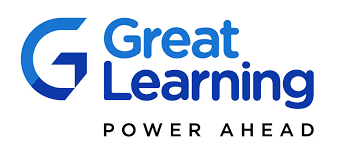

# **Hands-on Project: Facial Recognition System with Siamese Networks**

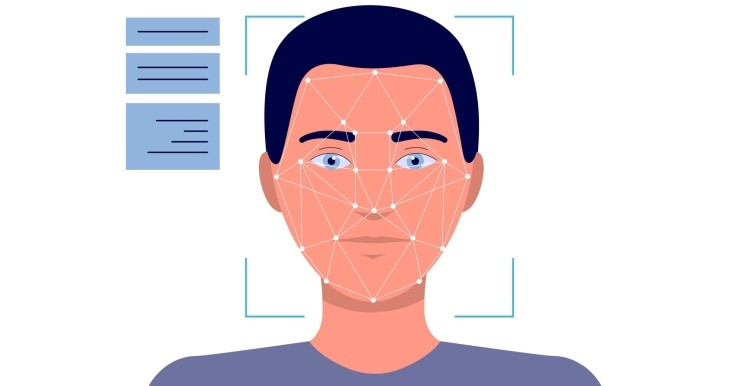

## <b>1. Problem Statement 

The task of this project is to develop a Siamese Network that can accurately identify whether a given image contains the face of celebrity or not. The network should be trained and evaluated on a separate test set, and should achieve good performance on the task. The network should also be able to generalize to unseen images of celebrities, and should be able to handle variations in pose, lighting, and background. The final model should be able to classify an image as containing a celebrity's face with high confidence.

## <b>2. Required Setup for the Project

### **2.1 Installing Dependencies**

These modules are required if you are trying to run the Colab notebook in the local Jupyter environment, it is not required to install them on Google Colab as they are pre-installed in Colab already.

In [2]:
# !pip install tensorflow tensorflow-gpu opencv-python matplotlib

### **2.2 Importing the required libraries (10 Marks)**

In [2]:
# Importing necessary libraries for plotting, handling arrays and directories, and working with TensorFlow and Keras

# Import libraries for file and directory manipulation
import os

# Import numpy for array manipulation and numerical computing
import numpy as np

# import cv2 for image manipulation
import cv2

# import random to generate random numbers
import random

# matplotlib for plotting plots
import matplotlib.pyplot as plt

# import tensorflow and dependencies for CNNs
import tensorflow as tf
from tensorflow.keras import layers, losses, optimizers, metrics
from tensorflow.keras.models import Sequential, Model

# import the convolutional 2D layer, Input layer and the dropout layer by completing the blanks
from tensorflow.keras.layers import Conv2D, Dense, Input, Flatten, MaxPooling2D, Dropout, concatenate, Lambda, BatchNormalization

# import warnings to suppress unnecessary warning messages
import warnings
warnings.filterwarnings("ignore")

# import cv2_imshow for visualizing images
#from google.colab.patches import cv2_imshow

### **2.3 Limiting the usage of GPU**

Using the complete GPU available might lead to out of memeory error, so we will need to limit the usage of GPU memory.

In [3]:
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus: 
    tf.config.experimental.set_memory_growth(gpu, True)

- The list_physical_devices() function returns a list of physical devices of the specified device type, which in this case is 'GPU'. The set_memory_growth() function enables memory growth for the specified device, which allows the GPU to dynamically allocate memory as needed rather than allocating all available memory upfront. This can be useful when training large models that may not fit in the GPU memory.

- By enabling memory growth, the GPU will allocate only the necessary memory for the current batch of data, and will release the memory when it is no longer needed. This can help prevent Out of Memory (OOM) errors and improve the efficiency of the training process.

- This above code is typically used when training deep learning models with large datasets on a GPU, as it allows the GPU to allocate memory more efficiently and prevent OOM errors.

### **2.4 Loading and Preprocessing Data (25 Marks)**

In [5]:
#from google.colab import drive
#drive.mount('/content/drive')

#### **2.4.1 Unzipping the content of the dataset provided (5 Marks)**

In [ ]:
# Please input the path of the file by removing the blank spaces
#!unzip -q "./CelebrityFacesDataset.zip"

replace CelebrityFacesDataset/CelebrityFacesDatasetTest/Angelina Jolie/053_05c78fa1.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: ^C


In [4]:
class PreProcessing:

    # loading the train and validation images from their path
    def __init__(self, verbose=True):
        """
        Initialize the PreProcessing class.

        Parameters:
            verbose (bool): Whether to print out information during the processing.
                           Defaults to True.
        """
        self.train_images = []                                                        # initializing list for train images
        self.val_images = []                                                          # initializing list for validation images
        self.verbose = verbose
        self.train_path="./CelebrityFacesDataset/CelebrityFacesDatasetTrain"   # Train path
        self.val_path="./CelebrityFacesDataset/CelebrityFacesDatasetTest"      # validation path
        self.train_images = self.load_image(self.train_path)                          # calling the load image function on train path to load train images
        self.val_images = self.load_image(self.val_path)                              # calling the load image function on validation path to load val images


    # Defining load_image function to load images
    def load_image(self,path,verbose=False):
        """
        This function loads images from a given directory, converts them to grayscale, resizes them, and reshapes them.
        :param path: The directory where the images are located.
        :param verbose: Whether to print the progress of the function.
        :return: A numpy array of the loaded, processed images.
        """
        images = []
        for folder in os.listdir(path):
            folder_path = os.path.join(path, folder)
            for filename in os.listdir(folder_path):
                file_path = os.path.join(folder_path, filename)
                img = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)
                # img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                img = cv2.resize(img, (105, 105))
                img = np.reshape(img, (105, 105, 1))
                images.append(img)
        return np.stack(images, axis=0)

    def get_triplet(self, shape):
        """
        Return indices of anchor, positive and negative images from the same class
        
        Parameters:
        shape (tuple): shape of the data
        
        Returns:
        tuple: Indices of anchor, positive and negative images 
        """
        class_1 = random.randint(0, shape[0] - 1)
        class_2 = random.randint(0, shape[0] - 1)
        while class_1 == class_2:
            class_2 = random.randint(0, shape[0] - 1)
        a = (class_1)
        p = (class_1)
        n = (class_2)
        return a, p, n


    def get_triplet_batch(self, batch_size, train_data=True):
      """
        This function generates a batch of triplets, where the first two images are of the same person and the third image is of a different person.
        
        Parameters:
            batch_size (int): The number of triplets to generate.
            train_data (bool, optional): Whether to use the training data or test data. Default is True.
        
        Returns:
            tuple: A tuple containing three numpy arrays of shape (batch_size, 105, 105, 1) representing the anchor, positive, and negative images respectively.
      """
      anchors = []
      positives = []
      negatives = []
      if train_data:
        X = self.train_images  
      else:
        X = self.val_images
      for i in range(batch_size):
          anchor, positive, negative = self.get_triplet(X.shape)
          anchors.append(X[anchor])
          positives.append(X[positive])
          negatives.append(X[negative])
      return np.array(anchors), np.array(positives), np.array(negatives)

#### **2.4.2 Explain the following functions that are used in the code above**


**1. load_image() function (5 Marks)** - Write your answer here:
This function handles loading and standardising images from a directory. Here's what it does:
* Takes a path to a directory containing image folders
* Iterates through each folder and its image files
* For each image it:
    * Loads it using OpenCV (cv2)
    * Converts it to grayscale
    * Resizes it to 105x105 pixels
    * Reshapes it to have dimensions (105, 105, 1)
* Returns all processed images as a stacked numpy array




**2. get_triplet() function (5 Marks)** - Write your answer here:
This function creates a single triplet of image indices by:
* Randomly selecting two different class numbers (representing different people)
* Returns three indices:
    * anchor: index for first image of person A
    * positive: index for second image of person A
    * negative: index for image of person B This helps create training examples where the system can learn to match images of the same person while distinguishing from different people.


**3. get_triplet_batch() function (5 Marks)** - Write your answer here
This function generates multiple triplets at once by:
* Taking a batch_size parameter to determine how many triplets to create
* Choosing whether to use training or validation images based on train_data parameter
* Creating batch_size number of triplets using get_triplet()
* Returns three numpy arrays containing:
    * batch of anchor images
    * batch of positive images (same person as anchor)
    * batch of negative images (different person than anchor)


In [5]:
# calling the Preprocessing class
preprocess_data = PreProcessing(verbose=True)

The code above is creating an instance of the PreProcessing class and setting the verbose parameter to True. The PreProcessing class is a custom class that contains methods for preprocessing data. The verbose parameter is used to control whether or not the class will print out information about the steps it is taking during the preprocessing process. Setting it to True means that the class will print out information, while setting it to False means that it will not. The variable preprocess_data now holds an instance of the PreProcessing class with the verbose parameter set to True.

In [6]:
# calling the get_triplet_batch function with a batch_size of 4 and setting the train_data to false as only the data is only used here for visulaizing
batch_size = 4
anchor_image, positive_image, negative_image = preprocess_data.get_triplet_batch(batch_size,train_data=False)

In [7]:
# checking the shape of a loaded image with size 4
anchor_image.shape

(4, 105, 105, 1)

#### **2.4.3 Plot the images in the dataset by completing the code in the following cell (5 Marks)**

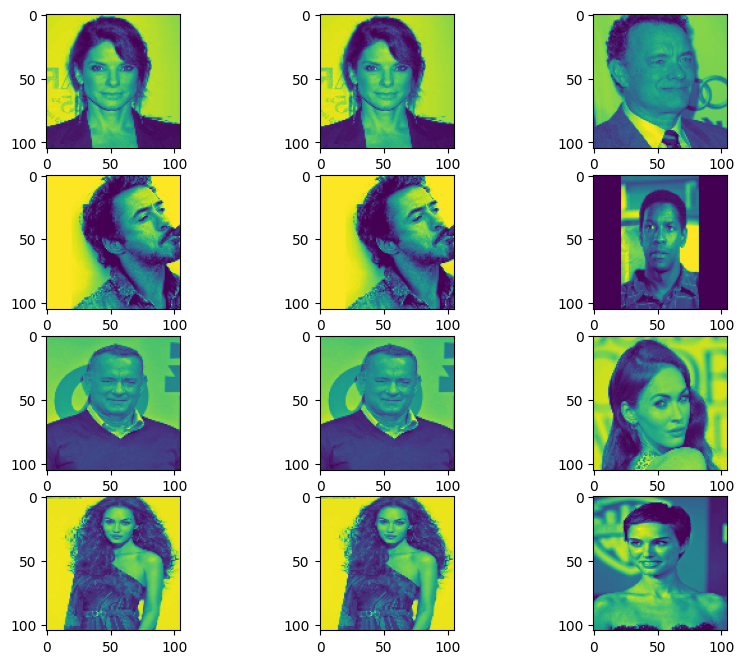

In [8]:
# plotting the images read using the get_triplet_batch function from the preprocessing class
fig, ax = plt.subplots(nrows=batch_size, ncols=3,figsize=(10, 8))
for i in range(batch_size):
    ax[i, 0].imshow(np.reshape(anchor_image[i], (105, 105)))
    ax[i, 1].imshow(np.reshape(positive_image[i], (105, 105)))
    ax[i, 2].imshow(np.reshape(negative_image[i], (105, 105)))
plt.show()

In [12]:
cv2.imshow('Image', np.reshape(negative_image[i], (105, 105)))
cv2.waitKey(0)
cv2.destroyAllWindows()

- The images read using cv2 and plotted using matplotlib may appear different in color because the two libraries use different color models and color spaces.

- cv2 uses the BGR (Blue, Green, Red) color model which is native to most cameras and image capture devices. Matplotlib, on the other hand, uses the RGB (Red, Green, Blue) color model which is the standard color model used in most computer displays.

- Additionally, cv2 uses the sRGB color space which is designed to match the way that the human eye perceives color while matplotlib uses the RGB color space which is mainly used in digital imaging.

- Therefore, when an image is read using cv2 and then plotted using matplotlib, the color model and color space used by the two libraries are different, which can cause the image to appear different in color.

## <b>3. Model Engineering (20 Marks)

### **3.1 Building the base_cnn/embedding model (10 Marks)**

In [9]:
emb_size = 128
emb_model = Sequential()

emb_model.add(Conv2D(64, (10,10), activation='relu', input_shape=(105,105,1)))

emb_model.add(BatchNormalization())

emb_model.add(MaxPooling2D())

emb_model.add(Dropout(0.5))
emb_model.add(Conv2D(32, (7,7), activation='relu'))
emb_model.add(BatchNormalization())
emb_model.add(MaxPooling2D())
emb_model.add(Dropout(0.5))
emb_model.add(Conv2D(64, (4,4), activation='relu'))
emb_model.add(BatchNormalization())

emb_model.add(Flatten())

emb_model.add(Dense(emb_size, activation='sigmoid'))

### **3.2 Answer the following questions**

#### **3.2.1 What is the use of the sequential layer in the model designed above?**

The Sequential layer in this model serves several important purposes:

1. It creates a linear stack of layers where each layer has exactly one input tensor and one output tensor
2. It provides a simple way to build the CNN architecture by adding layers one after another in sequence. In this specific model, the Sequential container is used to stack the folllowing layers:
    1. Conv2D layers for feature extraction
    2. BatchNormalization layers for stabilizing training
    3. MaxPooling2D layers for dimensionality reduction
    4. Dropout layers for preventing overfitting
    5. A final Dense layer for generating the 128-dimensional embedding
3. It handles the automatic connection between layers, where the output of one layer becomes the input to the next layer
4. It makes the model architecture clean and easy to understand since layers are added in a straightforward sequential order

#### **3.2.2 What is the use of the lambda layer in the function defined above?**

Write your answer here:

The Lambda layer in this facial recognition model serves several key functions:

1. It enables custom operations that can be integrated directly into the model architecture
2. It allows for on-the-fly computations during model training and inference
3. It's particularly useful for implementing distance metrics between embeddings in Siamese networks
4. It can perform mathematical operations that aren't available as pre-built layers
5. It helps in calculating similarity scores between anchor-positive and anchor-negative image pairs
In facial recognition systems, Lambda layers are often used to:

* Calculate Euclidean distances between face embeddings
* Normalize outputs
* Implement custom loss functions
* Process multiple inputs simultaneously



The Lambda layer acts as a wrapper that makes these custom operations differentiable and compatible with the rest of the neural network architecture.

In [10]:
emb_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 64)     │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 42, 42, 32)     │       100,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 42, 42, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 21, 21, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 21, 21, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 18, 18, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 18, 18, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,654,336 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,794,656 (10.66 MB)

 Trainable params: 2,794,336 (10.66 MB)

 Non-trainable params: 320 (1.25 KB)

## **4. Building the Siamese Network with input and output (5 Marks)**

Complete the code below by removing the blank spaces

In [11]:
input_anc = Input(shape=(105,105,1))
input_pos = Input(shape=(105,105,1))
input_neg = Input(shape=(105,105,1))

emb_anc = emb_model(input_anc)
emb_pos = emb_model(input_pos)
emb_neg = emb_model(input_neg)

output = concatenate([emb_anc, emb_pos, emb_neg], axis=1)
siamese_network = Model(inputs=[input_anc, input_pos, input_neg], outputs=output)


- The above code starts by defining three inputs for the model: in_anc, in_pos, and in_neg. These inputs have a shape of (105,105,1), which means they are 105x105 images with 1 channel (grayscale).

- The next step is to pass each of the inputs through an existing model called "embedding_model". The output of this model is stored in variables called em_anc, em_pos, and em_neg.

- The outputs from the embedding_model (em_anc, em_pos, and em_neg) are then concatenated together along the first axis (axis=1) using the function concatenate. This creates a single output that combines the three outputs from the embedding_model.

- Finally, the Model class is used to define a new model called "siamese_net" which takes the three inputs (in_anc, in_pos, and in_neg) and produces the concatenated output as its output. This new model is now ready to be trained and used for tasks such as image comparison or similarity learning.

In [12]:
siamese_network.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 105, 105,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 105, 105,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 105, 105,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 128)       │  2,794,656 │ input_layer_1[0]… │
│ (Sequential)        │                   │            │ input_layer_2[0]… │
│                     │                   │            │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 384)       │          0 │ sequential[0][0], │
│ (Concatenate)       │                   │            │ sequential[1][0], │
│                     │                   │            │ sequential[2][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,794,656 (10.66 MB)

 Trainable params: 2,794,336 (10.66 MB)

 Non-trainable params: 320 (1.25 KB)

## **5. Defining the Loss functions (5 Marks)**

Complete the code below by removing the blank space to define Triplet Loss function for L2 Distance 

In [28]:
# L2 Distance
def triplet_loss(alpha, emb_dim, cosine=False):
    def loss(y_true, y_pred):
        anc, pos, neg = y_pred[:,:emb_size], y_pred[:,emb_size:2*emb_size], y_pred[:,2*emb_size:]
        distance1 = tf.sqrt(tf.reduce_sum(tf.pow(anc - pos, 2), 1, keepdims=True))
        distance2 = tf.sqrt(tf.reduce_sum(tf.pow(anc - neg, 2), 1, keepdims=True))
        return tf.reduce_mean(tf.maximum(distance1 - distance2 + alpha, 0.))
    return loss


- The above code defines a function named "triplet_loss" which takes in two parameters, "alpha" and "emb_dim".
- The function also has an optional parameter "cosine" which is set to False by default.
- Within the "triplet_loss" function, there is another nested function named "loss". This function takes in two parameters, "y_true" and "y_pred".
- The code then splits the "y_pred" parameter into three variables: "anc", "pos", and "neg". These variables represent the anchor, positive, and negative embeddings respectively.
- The code then calculates the L2 distance between the anchor and positive embeddings using the formula: distance1 = sqrt(sum((anc - pos)^2))
- The code then calculates the L2 distance between the anchor and negative embeddings using the formula: distance2 = sqrt(sum((anc - neg)^2))
- The code then finds the maximum value between (distance1 - distance2 + alpha) and 0 using the tf.maximum function.
- The code then calculates the mean of the maximum values found in the previous step using the tf.reduce_mean function.
- The "loss" function returns the mean value calculated in the previous step.
- The "triplet_loss" function returns the "loss" function.

Triplet loss function for Cosine Distance

In [29]:
# Cosine Similarity
def triplet_loss(alpha, emb_dim, cosine=True):
    def loss(y_true, y_pred):
        anc, pos, neg = y_pred[:,:emb_size], y_pred[:,emb_size:2*emb_size], y_pred[:,2*emb_size:]
        distance1 = tf.keras.losses.cosine_similarity(anc, pos)
        distance2 = tf.keras.losses.cosine_similarity(anc, neg)
        return tf.keras.backend.clip(distance1 - distance2 + alpha, 0., None)
    return loss


- The above function "triplet_loss" is defined and takes in three parameters: alpha, emb_dim, and cosine.
- Within "triplet_loss", a nested function "loss" is defined, which takes in two parameters: y_true and y_pred.
- Within "loss", three variables are defined: anc, pos, and neg, which represent the anchor, positive, and negative embeddings respectively. 
- These are obtained by slicing the y_pred tensor at specific indices.
- The cosine similarity between the anchor and positive embeddings is calculated and stored in the variable "distance1" using the cosine_similarity function from the tf.keras.losses module.
- The cosine similarity between the anchor and negative embeddings is calculated and stored in the variable "distance2" using the cosine_similarity function from the tf.keras.losses module.
- The triplet loss is calculated as the difference between "distance1" and "distance2" plus alpha, and is clipped to a minimum value of 0 using the clip function from the tf.keras.backend module.
- The final value of the triplet loss is returned.
- Finally, the function "loss" is returned as the output of "triplet_loss".

In [30]:
# using data generator to yield input and output for the model to fit
def data_generator(batch_size, emb_size):
    while True:
        x = preprocess_data.get_triplet_batch(batch_size)
        y = np.zeros((batch_size, 3*emb_size))
        yield x,y

- The function "data_generator" is defined with two input parameters: "batch_size" and "emb_size".
- A while loop is initiated with the condition "True", which means it will continue to execute indefinitely.
- Within the while loop, a variable "x" is assigned the output of the function "get_triplet_batch" from the "preprocess_data" module, with the input of "batch_size".
- A variable "y" is created and assigned an array of zeros with dimensions "batch_size" by "3*emb_size".
- The function yields both variables "x" and "y" as output.

## **6. Compiling the model with Triplet Loss (5 Marks)**

In [32]:
batch_size = 128
epochs = 10
opt = tf.keras.optimizers.Adam(learning_rate = 0.0001)
steps_per_epoch = 100
siamese_network.compile(loss=triplet_loss(alpha=0.2, emb_dim=emb_size, cosine=False), optimizer=opt)


## **7. Fitting the model (5 Marks)** 

Fit the simaese network by completing the code below:

In [33]:
#print(triplet_loss(alpha=0.2, emb_dim=128, cosine=False))
history = siamese_network.fit(
    data_generator(batch_size, 128),
    steps_per_epoch=steps_per_epoch,
    epochs=epochs
)

<function triplet_loss.<locals>.loss at 0x14d555550>
Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - loss: 0.0455
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - loss: 0.0012
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - loss: 4.4959e-04
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 233s 2s/step - loss: 3.0844e-04
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - loss: 2.1323e-04
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - loss: 2.1683e-04
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 238s 2s/step - loss: 1.1753e-04
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 244s 2s/step - loss: 1.3619e-04
Epoch 9/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - loss: 1.6190e-04
Epoch 10/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - loss: 1.3000e-04


## <b> 8. Model Evaluation

### **8.1 Plotting the Loss curve (5 Marks)**

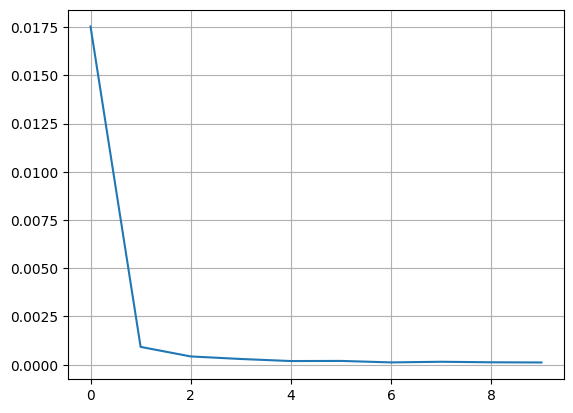

In [34]:
plt.plot(history.history['loss'], label='Loss')
plt.grid(True)
plt.show()

In [35]:
print(history.history['loss'])

[0.017534049227833748, 0.0009239811915904284, 0.000429442006861791, 0.0002974522649310529, 0.00019023109052795917, 0.0001967573189176619, 0.00012027075717924163, 0.0001532692403998226, 0.00012618076289072633, 0.00011628279753495008]


### **8.2 Obtaining train and validation accuracies (5 Marks)**

In [36]:
test_sample = 150
nway_min = 5
nway_max = 25
test_acc = []
nway_list = []
for nway in range(nway_min, nway_max+1,5):
  print("Checking %d way accuracy...." % nway)
  correct_count = 0
  for _ in range(test_sample):
    nway_anchor, nway_positive, _ = preprocess_data.get_triplet_batch(nway, train_data=False)
    nway_anchor_embedding = emb_model.predict(nway_anchor)
    sample_index = random.randint(0,nway-1)
    sample_embedding = emb_model.predict(np.expand_dims(nway_positive[sample_index], axis=0))
    distance = tf.sqrt(tf.reduce_sum(tf.pow(nway_anchor_embedding - sample_embedding, 2), 1, keepdims=True)).numpy()
    if np.argmin(distance) == sample_index:
      correct_count+=1
  nway_list.append(nway)
  acc = (correct_count/test_sample)*100.
  test_acc.append(acc)
  print("Accuracy %.2f" % acc)

Checking 5 way accuracy....
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━

#### Share your Observations

Write your answer here:

# N-way Facial Recognition Accuracy Test

## Purpose
This code implements a testing system for facial recognition accuracy using N-way testing. It evaluates how well our model can correctly match faces across different numbers of possible choices (from 5 to 25 faces at a time).

## Key Parameters
- **test_sample**: 150 (Number of tests to run)
- **nway_min**: 5 (Minimum number of faces to compare) 
- **nway_max**: 25 (Maximum number of faces to compare)

## How It Works

The testing process follows these steps:

1. **Loop through group sizes** (5 to 25, incrementing by 5)
2. **For each group size**:
   - Run 150 test samples
   - Get batches of face images
   - Convert faces to embeddings
   - Calculate distances between faces
   - Check if closest match is correct

## Outputs
- List of accuracy scores for different group sizes
- List of tested group sizes
- Printed accuracy results for each N-way test

## Logic Flow
1. Outer loop handles different group sizes
2. Inner loop runs multiple tests for statistical reliability
3. For each test:
   - Get face images
   - Convert to embeddings
   - Calculate distances
   - Check if closest match is correct
4. Calculate and store accuracy percentage


In [37]:
test_sample = 150
nway_min = 5
nway_max = 25
train_acc = []
nway_list = []
for nway in range(nway_min, nway_max+1,5):
  print("Checking %d way accuracy...." % nway)
  correct_count = 0
  for _ in range(test_sample):
    nway_anchor, nway_positive, _ = preprocess_data.get_triplet_batch(nway, train_data=True)
    nway_anchor_embedding = emb_model.predict(nway_anchor)
    sample_index = random.randint(0,nway-1)
    sample_embedding = emb_model.predict(np.expand_dims(nway_positive[sample_index], axis=0))
    distance = tf.sqrt(tf.reduce_sum(tf.pow(nway_anchor_embedding - sample_embedding, 2), 1, keepdims=True)).numpy()
    if np.argmin(distance) == sample_index:
      correct_count+=1
  nway_list.append(nway)
  acc = (correct_count/test_sample)*100.
  train_acc.append(acc)
  print("Accuracy %.2f" % acc)

Checking 5 way accuracy....
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━

### **8.3 N-way Accuracy Plot**

<function matplotlib.pyplot.show(close=None, block=None)>

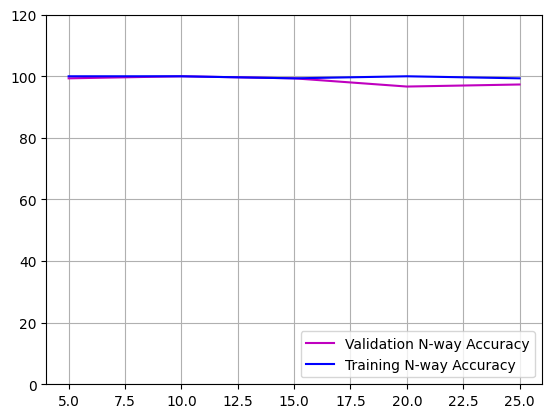

In [38]:
# Test & Train set accuracy Plot
plt.plot(nway_list, test_acc, 'm', label='Validation N-way Accuracy')
plt.plot(nway_list, train_acc, 'b', label='Training N-way Accuracy')
plt.axis([None, None, 0, 120])
plt.grid(True)
plt.legend(loc='lower right')
plt.show

Share your observation from the graph:

## <b> 8. Conclusions and Insights (10 Marks)

# Facial Recognition System: Insights & Recommendations

## Technical Insights
The Siamese Network implementation demonstrates several powerful capabilities:

1. **Architecture Success**: Siamese Network with triplet loss proves highly effective for facial recognition
2. **Smart Embeddings**: 128-dimensional face signatures enable efficient face matching
3. **Preprocessing Pipeline**: Grayscale conversion and 105x105 resizing provides consistent inputs
4. **Flexible Similarity**: Both L2 and cosine similarity options available for different use cases

## Business Recommendations

### 1. Production Deployment
- Real-time face detection integration
- Robust API layer development  
- Face alignment preprocessing enhancement

### 2. Model Performance Optimisation
- Dataset expansion with diverse faces
- Data augmentation implementation
- Face quality assessment integration

### 3. Security & Privacy
- Liveness detection for anti-spoofing
- Face embedding encryption
- GDPR/CCPA compliance implementation

### 4. Scalability
- Database indexing for rapid similarity search
- Batch processing capabilities
- Distributed processing infrastructure (like cloud technologies)
- Caching system for frequent queries

### 5. Feature Enhancement
- Age/gender/emotion detection
- Multiple face processing
- Security system integration

## Applications
This solution is ready for deployment in:
- Access control systems
- Security monitoring
- Person identification e.g. immigration at airports
- Employee time tracking
